# DensGNN: ablação de adaptive, core e border

Figura com quatro painéis (**NMI, ARI, ACC e F1-macro**) em **Cora, CiteSeer e PolBlogs**. A primeira figura mostra pontos individuais das seeds e média ± desvio padrão amostral por variante. As figuras seguintes apresentam um boxplot por métrica: os datasets estão no eixo X e as cores identificam adaptive, core e border. Os valores são lidos dos CSVs existentes; nenhum treino é iniciado.

A análise estatística usa Friedman com pareamento explícito e duas perguntas:

- **Por dataset:** existe diferença entre as variantes nesse grafo, considerando as três seeds pareadas?
- **Entre datasets:** existe diferença sistemática entre variantes usando um valor médio por dataset?

Abra a partir da raiz do repositório ou de `scripts/` e execute todas as células para atualizar o retrato dos resultados. Os caminhos e seeds esperadas vêm dos nove YAMLs em `configs/ablation_distance/`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import itertools
import json
import math
import sys
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import scipy
from scipy.stats import friedmanchisquare, permutation_test
import yaml
from IPython.display import display, Markdown


def find_repo_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "ablation_distance").is_dir() and (candidate / "scripts" / "main.py").is_file():
            return candidate
    raise FileNotFoundError("Abra o notebook a partir da raiz do repositório ou scripts/.")


ROOT = find_repo_root()
CONFIG_DIR = ROOT / "configs/ablation_distance"
RESULTS_ROOT = ROOT / "results/ablation_distance"
EXPORT_DIR = RESULTS_ROOT / "analysis"
DATASETS = ["cora", "citeseer", "polblogs"]
VARIANTS = ["adaptive", "core", "border"]
METRICS = ["nmi", "ari", "acc", "f1_macro"]
DATASET_NAMES = {"cora": "Cora", "citeseer": "CiteSeer", "polblogs": "PolBlogs"}
METRIC_NAMES = {"nmi": "NMI", "ari": "ARI", "acc": "ACC", "f1_macro": "F1-macro"}
COLORS = {"adaptive": "#0072B2", "core": "#009E73", "border": "#D55E00"}
ALPHA = 0.05
N_RESAMPLES = 49999  # Com 3 variantes e 3 blocos: 6**3 = 216 permutações, enumeração exata.
PERMUTATION_SEED = 42  # Usada somente se a análise crescer e exigir Monte Carlo.
PERCENT_SCORES = True
Y_LIMITS = (0, 100)  # Unidades exibidas; use None para limites automáticos.
# Boxplot: None usa as seeds dos YAMLs, como os testes e a figura de médias.
# Para incluir os dois lotes, use [2026, 2027, 2028, *range(2030, 2037)].
# BOXPLOT_SEEDS = None
BOXPLOT_SEEDS = [2026, 2027, 2028, *range(2030, 2037)]
BOXPLOT_METRICS = METRICS.copy()  # Use ["nmi"] para gerar somente o boxplot de NMI.
BOXPLOT_SHOW_POINTS = False  # True sobrepõe as observações individuais às caixas.
SAVE_EXPORTS = True
SNAPSHOT_UTC = datetime.now(timezone.utc).isoformat()
if len(VARIANTS) < 3 or not 0 < ALPHA < 1 or N_RESAMPLES < 1:
    raise ValueError("Friedman requer >=3 variantes; ALPHA deve estar em (0,1) e N_RESAMPLES >=1.")
print(f"Retrato UTC: {SNAPSHOT_UTC}\nResultados: {RESULTS_ROOT}")

Retrato UTC: 2026-10-26T17:51:14.989388+00:00
Resultados: /home/gmessias/NodeClusteringAlgorithms/results/ablation_distance


## Leitura, tentativas e cobertura

Somente `status=success` e scores finitos entram nas médias. A última tentativa bem-sucedida por dataset/variante/seed é selecionada, mesmo se uma tentativa posterior falhar; sem sucesso, conserva-se a última falha no relatório. A ordenação usa o `run_id` com timestamp. Tentativas substituídas e falhas ficam disponíveis para auditoria.

São lidos somente `runs/*/metrics.csv` de cada combinação indicada nos YAMLs; CSVs agregados e exportações da análise não são misturados às runs. Seeds fora das configuradas, identificadores incompatíveis e arquivos incompletos são registrados e ignorados. Grupos sem resultados permanecem na tabela como pendentes. Se houver métricas indefinidas, seu número válido pode ser menor que o número de runs com sucesso.

In [2]:
def repo_path(value):
    value = Path(value).expanduser()
    return (value if value.is_absolute() else ROOT / value).resolve()


def read_specs():
    specs, config_rows, config_issues = [], [], []
    signatures = {}
    for dataset, variant in itertools.product(DATASETS, VARIANTS):
        path = CONFIG_DIR / dataset / f"{variant}.yaml"
        config = yaml.safe_load(path.read_text(encoding="utf-8"))
        experiment = config["experiment"]
        params = config["models"]["densgnn"]["params"]
        enabled = [m for m, s in config["models"].items() if s.get("enabled", False)]
        if enabled != ["densgnn"] or params.get("point_selection") != variant:
            raise ValueError(f"O YAML deve habilitar só densgnn e point_selection={variant}: {path}")
        if int(experiment["runs"]) < 1:
            raise ValueError(f"Número de runs inválido: {path}")
        result_path = repo_path(experiment["output_root"]) / experiment["dataset"]
        if not result_path.is_relative_to(RESULTS_ROOT.resolve()):
            raise ValueError(f"Saída fora de results/ablation_distance/: {path}")
        seeds = list(range(int(experiment["seed"]), int(experiment["seed"]) + int(experiment["runs"])))
        spec = dict(dataset=dataset, variant=variant, saved_dataset=str(experiment["dataset"]),
                    seeds=seeds, result_path=result_path, config_file=path,
                    csv_filename=config["output"].get("csv_filename", "metrics.csv"))
        specs.append(spec)
        config_rows.append({"dataset": dataset, "variant": variant, "seeds": seeds,
                            "expected_runs": len(seeds), "result_path": str(result_path), "config_file": str(path)})
        # Todos os campos, exceto o identificador e point_selection, devem ser iguais por dataset.
        normalized = json.loads(json.dumps(config))
        normalized["experiment"].pop("dataset")
        normalized["models"]["densgnn"]["params"].pop("point_selection")
        signature = json.dumps(normalized, sort_keys=True)
        if dataset in signatures and signatures[dataset] != signature:
            config_issues.append({"dataset": dataset, "variant": variant,
                                  "detail": "Há diferenças de configuração além de point_selection; revisar a comparação controlada."})
        signatures.setdefault(dataset, signature)
    return specs, pd.DataFrame(config_rows), pd.DataFrame(config_issues)


def load_attempts(specs):
    rows, issues = [], []
    for spec in specs:
        files = sorted((spec["result_path"] / "runs").glob(f"*/{spec['csv_filename']}"))
        for path in files:
            try:
                frame = pd.read_csv(path, skipinitialspace=True)
                if frame.empty or not {"model", "seed", "status"}.issubset(frame):
                    raise ValueError("CSV vazio ou sem model, seed ou status")
                for position, values in frame.iterrows():
                    model = str(values["model"]).strip()
                    status = str(values["status"]).strip().lower()
                    seed = pd.to_numeric(values["seed"], errors="coerce")
                    saved_dataset = values.get("dataset", spec["saved_dataset"])
                    reason = None
                    if model != "densgnn":
                        reason = f"Modelo inesperado: {model}"
                    elif pd.isna(seed) or not np.isfinite(seed) or float(seed) != int(seed):
                        reason = "Seed incompleta/inválida"
                    elif int(seed) not in spec["seeds"]:
                        reason = f"Seed {seed} fora da configuração"
                    elif status not in {"success", "failed", "oot", "timeout"}:
                        reason = f"Status incompleto/inválido: {status}"
                    elif pd.notna(saved_dataset) and str(saved_dataset).strip() != spec["saved_dataset"]:
                        reason = "Dataset do CSV difere do YAML"
                    if reason:
                        issues.append({"path": str(path), "row": position, "detail": reason})
                        continue
                    run_id = values.get("run_id", path.parent.name)
                    row = {"dataset": spec["dataset"], "variant": spec["variant"], "seed": int(seed),
                           "status": status, "run_id": str(run_id) if pd.notna(run_id) else path.parent.name,
                           "error": values.get("error", ""), "metrics_file": str(path), "csv_row": position}
                    for metric in METRICS:
                        value = pd.to_numeric(values.get(metric, np.nan), errors="coerce")
                        row[metric] = float(value) if pd.notna(value) and np.isfinite(value) else np.nan
                    rows.append(row)
            except (OSError, ValueError, pd.errors.ParserError) as exc:
                issues.append({"path": str(path), "row": None, "detail": str(exc)})
    columns = ["dataset", "variant", "seed", "status", "run_id", "error", "metrics_file", "csv_row", *METRICS]
    attempts = pd.DataFrame(rows, columns=columns)
    attempts["_row"] = np.arange(len(attempts))
    attempts["_success"] = attempts["status"].eq("success").astype(int)
    selected = attempts.sort_values(["_success", "run_id", "metrics_file", "csv_row"], kind="stable").drop_duplicates(
        ["dataset", "variant", "seed"], keep="last"
    ).copy()
    return attempts, selected, pd.DataFrame(issues, columns=["path", "row", "detail"])


specs, config_inventory, config_issues = read_specs()
attempts, selected, load_issues = load_attempts(specs)
failed = attempts.loc[attempts["status"].ne("success")].copy()
discarded = attempts.loc[~attempts["_row"].isin(selected["_row"])].copy()
coverage_rows, summary_rows = [], []
for spec in specs:
    group = selected.loc[selected["dataset"].eq(spec["dataset"]) & selected["variant"].eq(spec["variant"])]
    success = group.loc[group["status"].eq("success")]
    coverage_rows.append({"dataset": spec["dataset"], "variant": spec["variant"],
                          "expected_runs": len(spec["seeds"]), "n_selected": len(group), "n_success": len(success),
                          "n_failed": len(group) - len(success), "n_pending": len(spec["seeds"]) - len(group)})
    for metric in METRICS:
        values = success[metric].dropna()
        summary_rows.append({"dataset": spec["dataset"], "variant": spec["variant"], "metric": metric,
                             "mean": values.mean(), "std": values.std(ddof=1), "n_valid": len(values),
                             "expected_runs": len(spec["seeds"]), "complete": len(values) == len(spec["seeds"])})
coverage = pd.DataFrame(coverage_rows)
summary = pd.DataFrame(summary_rows)
print(f"Tentativas: {len(attempts)}; sucessos selecionados: {selected['status'].eq('success').sum()}; retries substituídos: {len(discarded)}")
display(coverage)
for name, frame in [("Configurações com diferenças", config_issues), ("Arquivos/linhas ignorados", load_issues),
                    ("Tentativas sem sucesso", failed)]:
    if not frame.empty:
        display(Markdown(f"**{name}**"))
        display(frame)
if not config_issues.empty:
    warnings.warn("As variantes não diferem somente em point_selection; confira config_issues.")

Tentativas: 63; sucessos selecionados: 63; retries substituídos: 0


,dataset,variant,expected_runs,n_selected,n_success,n_failed,n_pending
0,cora,adaptive,7,7,7,0,0
1,cora,core,7,7,7,0,0
2,cora,border,7,7,7,0,0
3,citeseer,adaptive,7,7,7,0,0
4,citeseer,core,7,7,7,0,0
5,citeseer,border,7,7,7,0,0
6,polblogs,adaptive,7,7,7,0,0
7,polblogs,core,7,7,7,0,0
8,polblogs,border,7,7,7,0,0


**Arquivos/linhas ignorados**

,path,row,detail
0,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2026 fora da configuração
1,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2027 fora da configuração
2,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2028 fora da configuração
3,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2026 fora da configuração
4,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2027 fora da configuração
5,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2028 fora da configuração
6,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2026 fora da configuração
7,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2027 fora da configuração
8,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2028 fora da configuração
9,/home/gmessias/NodeClusteringAlgorithms/result...,0,Seed 2026 fora da configuração


## Figura: resultados individuais, média e desvio padrão

As cores identificam as variantes. Pontos pequenos são as seeds; losangos e barras mostram média ± DP amostral (`ddof=1`). Grupos com uma única observação mostram a média sem barra de DP; grupos vazios mostram “sem dados”. A figura usa todos os sucessos disponíveis, inclusive grupos ainda incompletos; a tabela de cobertura registra os denominadores. Pontos são deslocados horizontalmente apenas para evitar sobreposição.

A análise estatística abaixo exige as seeds planejadas completas e pareadas. Portanto, um ponto já aparecer na figura não significa que aquele grupo já está disponível para inferência. Barras de DP não são intervalos de confiança nem um teste de significância.

metric                              nmi                   ari  \
dataset  variant                                                
citeseer adaptive  22.97 ± 3.53 (n=7/7)  19.95 ± 4.12 (n=7/7)   
         border    21.35 ± 6.19 (n=7/7)  17.92 ± 8.12 (n=7/7)   
         core      23.98 ± 3.58 (n=7/7)  20.12 ± 3.24 (n=7/7)   
cora     adaptive  51.12 ± 1.45 (n=7/7)  43.43 ± 3.72 (n=7/7)   
         border    51.26 ± 1.48 (n=7/7)  43.06 ± 3.82 (n=7/7)   
         core      49.77 ± 3.51 (n=7/7)  39.46 ± 5.21 (n=7/7)   
polblogs adaptive  28.92 ± 5.14 (n=7/7)  17.52 ± 9.74 (n=7/7)   
         border    29.13 ± 2.26 (n=7/7)  18.88 ± 5.99 (n=7/7)   
         core      21.90 ± 8.25 (n=7/7)   7.83 ± 2.77 (n=7/7)   

metric                              acc               f1_macro  
dataset  variant                                                
citeseer adaptive  44.66 ± 5.49 (n=7/7)   37.89 ± 8.33 (n=7/7)  
         border    46.85 ± 8.18 (n=7/7)  37.21 ± 11.22 (n=7/7)  
         core      45.26 ± 4.62 (n=7/7)   41.79 ± 5.48 (n=7/7)  
cora     adaptive  66.24 ± 4.26 (n=7/7)   62.55 ± 4.00 (n=7/7)  
         border    66.81 ± 3.85 (n=7/7)   64.85 ± 1.63 (n=7/7)  
         core      61.84 ± 6.27 (n=7/7)   61.06 ± 5.58 (n=7/7)  
polblogs adaptive  69.41 ± 6.65 (n=7/7)   65.56 ± 9.30 (n=7/7)  
         border    71.81 ± 8.52 (n=7/7)  68.56 ± 11.07 (n=7/7)  
         core      61.83 ± 2.91 (n=7/7)   55.65 ± 2.80 (n=7/7)

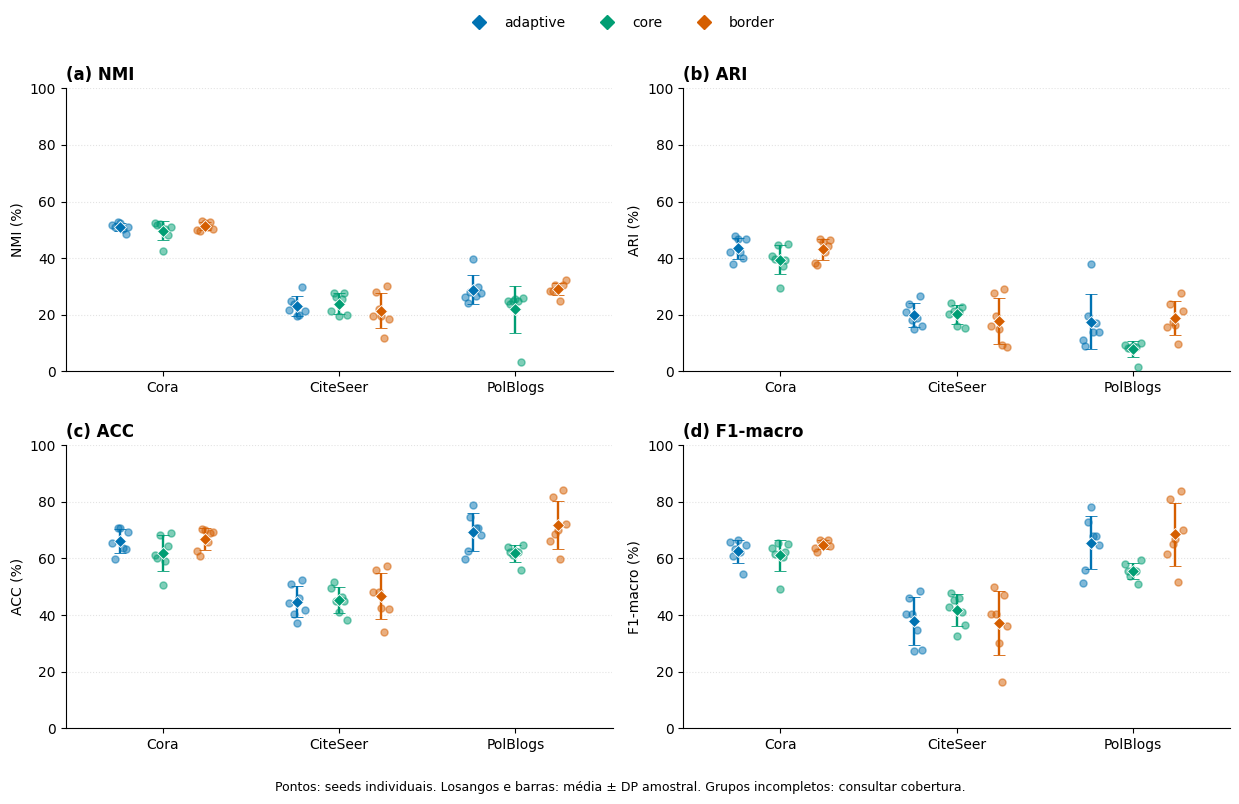

In [3]:
scale = 100 if PERCENT_SCORES else 1
plot_summary = summary.copy()
plot_summary[["mean", "std"]] *= scale
plot_summary["mean_sd"] = [
    "sem dados" if row.n_valid == 0 else
    f"{row.mean:.2f} (n=1; DP indefinido)" if row.n_valid == 1 else
    f"{row.mean:.2f} ± {row.std:.2f} (n={row.n_valid}/{row.expected_runs})"
    for row in plot_summary.itertuples(index=False)
]
display(plot_summary.pivot(index=["dataset", "variant"], columns="metric", values="mean_sd").reindex(columns=METRICS))

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8), squeeze=False)
offsets = dict(zip(VARIANTS, np.linspace(-0.24, 0.24, len(VARIANTS))))
successful = selected.loc[selected["status"].eq("success")]
for panel, (axis, metric) in enumerate(zip(axes.flat, METRICS)):
    for x, dataset in enumerate(DATASETS):
        for variant in VARIANTS:
            center = x + offsets[variant]
            row = summary.loc[summary["dataset"].eq(dataset) & summary["variant"].eq(variant) & summary["metric"].eq(metric)].iloc[0]
            runs = successful.loc[successful["dataset"].eq(dataset) & successful["variant"].eq(variant)].sort_values("seed")
            values = runs[metric].dropna().to_numpy() * scale
            if len(values):
                jitter = np.linspace(-0.045, 0.045, len(values)) if len(values) > 1 else np.array([0.0])
                axis.scatter(center + jitter, values, s=26, color=COLORS[variant], alpha=0.5, zorder=3)
                axis.errorbar(center, row["mean"] * scale,
                              yerr=row["std"] * scale if row["n_valid"] > 1 else None,
                              fmt="D", markersize=6, color=COLORS[variant], markeredgecolor="white",
                              markeredgewidth=0.6, capsize=4, linewidth=1.7, zorder=4)
            else:
                axis.text(center, 0.025, "sem dados", color=COLORS[variant], rotation=90,
                          ha="center", va="bottom", fontsize=8, transform=axis.get_xaxis_transform())
    axis.set_xticks(range(len(DATASETS)), [DATASET_NAMES.get(d, d) for d in DATASETS])
    axis.set_xlim(-0.55, len(DATASETS) - 0.45)
    axis.set_title(f"({chr(97 + panel)}) {METRIC_NAMES[metric]}", loc="left", fontweight="bold")
    axis.set_ylabel(f"{METRIC_NAMES[metric]}" + (" (%)" if PERCENT_SCORES else ""))
    if Y_LIMITS is not None:
        axis.set_ylim(*Y_LIMITS)
    axis.grid(axis="y", linestyle=":", alpha=0.35)
    axis.spines[["top", "right"]].set_visible(False)
legend = [Line2D([0], [0], marker="D", linestyle="none", color=COLORS[v], label=v, markersize=7) for v in VARIANTS]
fig.legend(handles=legend, loc="upper center", ncol=len(VARIANTS), frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.text(0.5, 0.015, "Pontos: seeds individuais. Losangos e barras: média ± DP amostral. Grupos incompletos: consultar cobertura.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.045, 1, 0.94), h_pad=2.0)
plt.show()
plt.close(fig)

## Boxplots individuais por métrica

Cada métrica é apresentada em uma figura independente. `BOXPLOT_METRICS = METRICS.copy()` gera as quatro figuras; use `BOXPLOT_METRICS = ["nmi"]` para gerar somente NMI, mantendo as métricas dos testes estatísticos. No eixo X estão **Cora, CiteSeer e PolBlogs**, e as cores representam **adaptive, core e border**.

A caixa vai do primeiro ao terceiro quartil (Q1–Q3), a linha interna indica a mediana e os bigodes alcançam as observações mais extremas dentro de 1,5 vezes o intervalo interquartil. Valores além dos bigodes aparecem como losangos. As caixas usam os scores das execuções individuais, não as médias por dataset.

Por padrão, `BOXPLOT_SEEDS = None` usa as mesmas seeds dos YAMLs e das demais análises. Para reunir os dois lotes neste gráfico, defina `BOXPLOT_SEEDS = [2026, 2027, 2028, *range(2030, 2037)]`. Essa opção afeta somente o boxplot; as tabelas de Friedman por permutação/Holm continuam usando as seeds configuradas nos YAMLs. A seção adicional de resultados diretos do SciPy usa as mesmas seeds selecionadas para o boxplot. O lote escolhido é registrado nos metadados exportados.

Grupos ausentes aparecem como “sem dados”; com uma observação, a caixa se reduz a uma linha. A tabela abaixo informa o número de valores por grupo. `BOXPLOT_SHOW_POINTS = True` permite sobrepor todas as observações.

Seeds do boxplot: [2026, 2027, 2028, 2030, 2031, 2032, 2033, 2034, 2035, 2036]


metric             nmi  ari  acc  f1_macro
dataset  variant                          
citeseer adaptive   10   10   10        10
         border     10   10   10        10
         core       10   10   10        10
cora     adaptive   10   10   10        10
         border     10   10   10        10
         core       10   10   10        10
polblogs adaptive   10   10   10        10
         border     10   10   10        10
         core       10   10   10        10

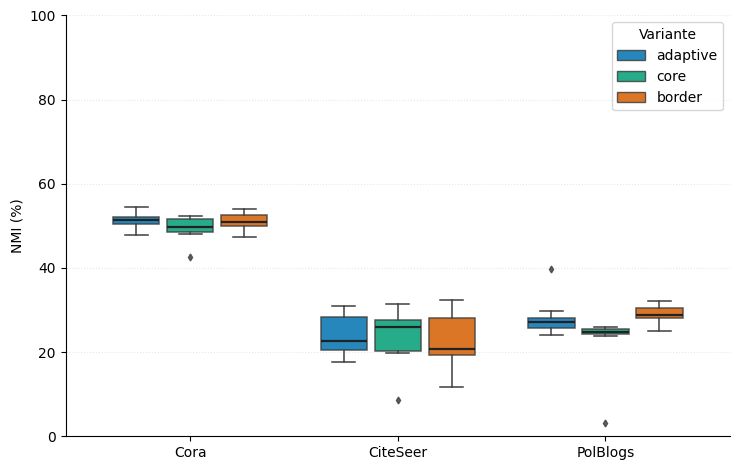

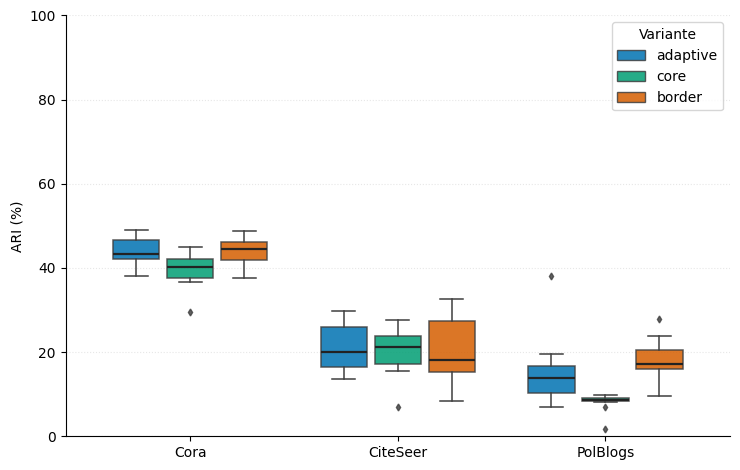

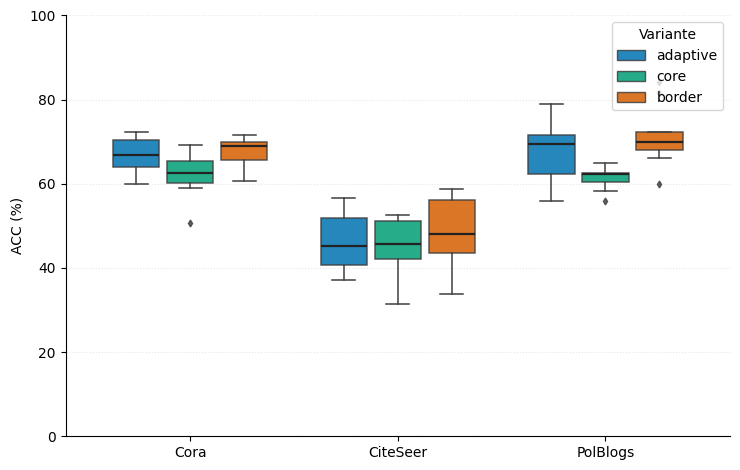

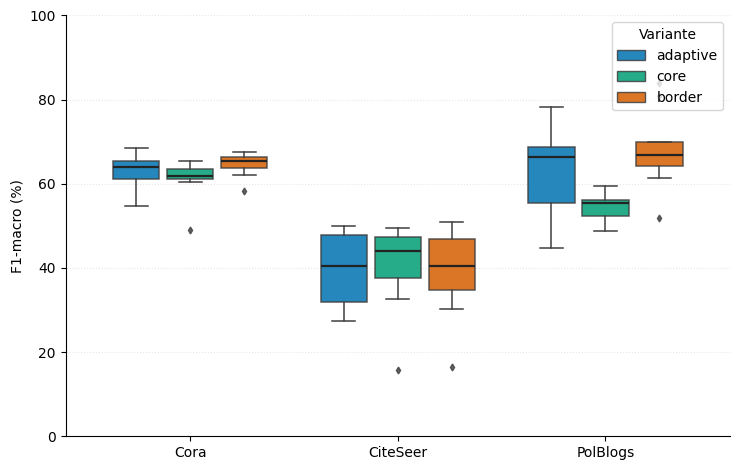

In [4]:
if BOXPLOT_SEEDS is None:
    boxplot_attempts, boxplot_selected = attempts.copy(), selected.copy()
    boxplot_load_issues = load_issues.copy()
    boxplot_seed_policy = "configured_yaml_seeds"
else:
    if (not isinstance(BOXPLOT_SEEDS, (list, tuple)) or not BOXPLOT_SEEDS
            or any(isinstance(seed, bool) or not isinstance(seed, int) for seed in BOXPLOT_SEEDS)
            or len(set(BOXPLOT_SEEDS)) != len(BOXPLOT_SEEDS)):
        raise ValueError("BOXPLOT_SEEDS deve ser None ou uma lista de seeds inteiras distintas.")
    boxplot_specs = [dict(spec, seeds=list(BOXPLOT_SEEDS)) for spec in specs]
    boxplot_attempts, boxplot_selected, boxplot_load_issues = load_attempts(boxplot_specs)
    boxplot_seed_policy = "explicit_boxplot_seeds"

boxplot_successful = boxplot_selected.loc[boxplot_selected["status"].eq("success")]
boxplot_values = boxplot_successful.melt(
    id_vars=["dataset", "variant", "seed", "run_id"], value_vars=METRICS,
    var_name="metric", value_name="score"
).dropna(subset=["score"])
boxplot_values["score_display"] = boxplot_values["score"] * (100 if PERCENT_SCORES else 1)
boxplot_index = pd.MultiIndex.from_product([DATASETS, VARIANTS, METRICS], names=["dataset", "variant", "metric"])
boxplot_counts = (boxplot_values.groupby(["dataset", "variant", "metric"]).size()
                  .reindex(boxplot_index, fill_value=0).rename("n").reset_index())
print("Seeds do boxplot:", "conforme os YAMLs" if BOXPLOT_SEEDS is None else BOXPLOT_SEEDS)
display(boxplot_counts.pivot(index=["dataset", "variant"], columns="metric", values="n").reindex(columns=METRICS))



if (not isinstance(BOXPLOT_METRICS, (list, tuple)) or not BOXPLOT_METRICS
        or len(set(BOXPLOT_METRICS)) != len(BOXPLOT_METRICS)
        or set(BOXPLOT_METRICS) - set(METRICS)):
    raise ValueError("BOXPLOT_METRICS deve ser uma lista não vazia de métricas distintas presentes em METRICS.")


def plot_distance_boxplot(values, metric):
    figure, axis = plt.subplots(figsize=(7.5, 4.8))
    group_width = 0.78
    box_width = group_width / len(VARIANTS)
    offsets = (np.arange(len(VARIANTS)) - (len(VARIANTS) - 1) / 2) * box_width
    for x, dataset in enumerate(DATASETS):
        for offset, variant in zip(offsets, VARIANTS):
            center = x + offset
            group = values.loc[values["dataset"].eq(dataset) & values["variant"].eq(variant)
                               & values["metric"].eq(metric)].sort_values("seed")
            scores = group["score_display"].to_numpy(dtype=float)
            if len(scores):
                axis.boxplot(
                    [scores], positions=[center], widths=box_width * 0.86,
                    patch_artist=True, manage_ticks=False, whis=1.5, showfliers=True,
                    boxprops={"facecolor": COLORS[variant], "edgecolor": "#3f3f3f", "linewidth": 1.1, "alpha": 0.85},
                    medianprops={"color": "#222222", "linewidth": 1.6},
                    whiskerprops={"color": "#3f3f3f", "linewidth": 1.1},
                    capprops={"color": "#3f3f3f", "linewidth": 1.1},
                    flierprops={"marker": "d", "markerfacecolor": "#444444", "markeredgecolor": "#444444",
                                "markersize": 3.5, "alpha": 0.85},
                )
                if BOXPLOT_SHOW_POINTS:
                    jitter = np.linspace(-box_width * 0.18, box_width * 0.18, len(scores))
                    axis.scatter(center + jitter, scores, s=17, facecolor="white", edgecolor=COLORS[variant],
                                 linewidth=0.9, alpha=0.8, zorder=4)
            else:
                axis.text(center, 0.025, "sem dados", color=COLORS[variant], rotation=90,
                          ha="center", va="bottom", fontsize=8, transform=axis.get_xaxis_transform())
    axis.set_xticks(range(len(DATASETS)), [DATASET_NAMES.get(d, d) for d in DATASETS])
    axis.set_xlim(-0.6, len(DATASETS) - 0.4)
    axis.set_ylabel(METRIC_NAMES[metric] + (" (%)" if PERCENT_SCORES else ""))
    if Y_LIMITS is not None:
        axis.set_ylim(*Y_LIMITS)
    axis.grid(axis="y", linestyle=":", alpha=0.3)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=COLORS[v], edgecolor="#3f3f3f", alpha=0.85, label=v)
               for v in VARIANTS]
    axis.legend(handles=handles, title="Variante", loc="upper right", frameon=True)
    figure.tight_layout()
    return figure, axis


boxplot_figures, boxplot_axes = {}, {}
for metric in BOXPLOT_METRICS:
    boxplot_figure, boxplot_axis = plot_distance_boxplot(boxplot_values, metric)
    boxplot_figures[metric] = boxplot_figure
    boxplot_axes[metric] = boxplot_axis
    plt.show()
    plt.close(boxplot_figure)


## SciPy Friedman: statistic and pvalue for the boxplot runs

This section calls `scipy.stats.friedmanchisquare` directly and prints its **statistic** and **unadjusted, asymptotic p-value** for every metric. Inputs are the original finite scores, paired by seed and ordered as `adaptive`, `core`, `border`.

**Data selection:** these tests use `boxplot_selected`, including the seeds selected by `BOXPLOT_SEEDS`. With the current explicit list, this means ten paired seeds (2026–2028 and 2030–2036) per dataset. When `BOXPLOT_SEEDS=None`, the YAML seed lists are used. The separate permutation/Holm section below continues to use the YAML-configured runs; results from different seed selections should not be mixed.

- **Within each dataset:** each block is one matched seed on the same graph.
- **Across datasets:** each block is one dataset; each cell is the mean over that dataset's selected seeds. The datasets are not pooled into 30 independent seed blocks.
- All planned selected seeds must have successful, finite observations in all three variants. Incomplete comparisons are printed as pending.
- The printed `pvalue` is exactly the chi-square approximation returned by SciPy, without permutation calibration or multiple-testing adjustment. It is an omnibus test and does not identify which pair differs. Small p-values should not be interpreted as proof that adaptive outperforms core or border. SciPy cautions about its p-value approximation with small numbers of blocks/conditions; this experiment has only three variants and three datasets.

Reference: [SciPy `friedmanchisquare`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html). The same finite raw scores give the same ranks whether displayed on a 0–1 or 0–100 scale.

In [4]:
def scipy_friedman_result(matrix, scope, dataset, metric, block_unit):
    values = matrix.to_numpy(dtype=float)
    complete = np.isfinite(values).all(axis=1)
    row = {"scope": scope, "dataset": dataset, "metric": metric, "block_unit": block_unit,
           "n_blocks": len(matrix), "n_complete_blocks": int(complete.sum()),
           "n_variants": len(VARIANTS), "statistic": np.nan, "pvalue": np.nan,
           "status": "pending", "reason": "Missing successful finite scores for selected blocks"}
    if len(matrix) < 2:
        row.update(status="insufficient", reason="At least two complete blocks are required")
    elif complete.all():
        # Each sample is one variant; the same row index represents the same block.
        with warnings.catch_warnings(record=True) as numerical_warnings:
            warnings.simplefilter("always", RuntimeWarning)
            result = friedmanchisquare(
                *(matrix[variant].to_numpy(dtype=float) for variant in VARIANTS),
                nan_policy="raise",
            )
        row.update(statistic=float(result.statistic), pvalue=float(result.pvalue))
        if np.isfinite(result.statistic) and np.isfinite(result.pvalue):
            row.update(status="computed", reason="")
        else:
            # Preserve SciPy's actual output, including its degenerate all-tied case.
            row.update(status="undefined", reason="; ".join(str(w.message) for w in numerical_warnings)
                       or "SciPy returned a nonfinite result")
    return row


scipy_friedman_rows = []
scipy_friedman_matrices = {}
scipy_friedman_seed_lists = {}
for dataset in DATASETS:
    dataset_specs = [spec for spec in specs if spec["dataset"] == dataset]
    planned = [list(BOXPLOT_SEEDS) if BOXPLOT_SEEDS is not None else list(spec["seeds"])
               for spec in dataset_specs]
    if any(seeds != planned[0] for seeds in planned[1:]):
        raise ValueError(f"Selected seeds differ between variants for {dataset}; align seeds before testing.")
    scipy_friedman_seed_lists[dataset] = planned[0]

for metric in METRICS:
    dataset_means = pd.DataFrame(np.nan, index=DATASETS, columns=VARIANTS)
    dataset_means.index.name = "dataset"
    for dataset in DATASETS:
        group = boxplot_selected.loc[boxplot_selected["dataset"].eq(dataset)
                                     & boxplot_selected["status"].eq("success")]
        matrix = group.pivot(index="seed", columns="variant", values=metric).reindex(
            index=scipy_friedman_seed_lists[dataset], columns=VARIANTS
        )
        scipy_friedman_matrices[(dataset, metric)] = matrix
        row = scipy_friedman_result(matrix, "within_dataset", dataset, metric, "paired_seed")
        scipy_friedman_rows.append(row)
        if np.isfinite(matrix.to_numpy(dtype=float)).all():
            dataset_means.loc[dataset] = matrix.mean(axis=0)
    scipy_friedman_matrices[("across_datasets", metric)] = dataset_means
    scipy_friedman_rows.append(scipy_friedman_result(
        dataset_means, "across_datasets", "all", metric, "dataset_mean"
    ))

scipy_friedman_results = pd.DataFrame(scipy_friedman_rows)
scipy_friedman_results["seed_policy"] = boxplot_seed_policy
scipy_friedman_results["pvalue_method"] = "scipy chi-square approximation; unadjusted"
print(f"scipy.stats.friedmanchisquare — SciPy {scipy.__version__}")
print("Variant order:", ", ".join(VARIANTS))
for dataset, seeds in scipy_friedman_seed_lists.items():
    print(f"{DATASET_NAMES.get(dataset, dataset)}: {len(seeds)} selected paired seeds = {seeds}")
for scope, title in [("within_dataset", "WITHIN EACH DATASET — blocks are paired seeds"),
                     ("across_datasets", "ACROSS DATASETS — blocks are dataset means")]:
    print("\n" + title)
    table = scipy_friedman_results.loc[scipy_friedman_results["scope"].eq(scope)]
    print(table[["dataset", "metric", "n_blocks", "n_complete_blocks", "statistic", "pvalue", "status"]]
          .to_string(index=False, float_format=lambda value: f"{value:.10g}"))
    incomplete = table.loc[~table["status"].eq("computed")]
    if not incomplete.empty:
        print(incomplete[["dataset", "metric", "reason"]].to_string(index=False))
print("\nThese p-values are unadjusted and asymptotic; they do not identify individual pairwise differences.")

if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    scipy_csv_path = EXPORT_DIR / "friedman_scipy_boxplot_runs.csv"
    scipy_friedman_results.to_csv(scipy_csv_path, index=False)
    scipy_matrix_dir = EXPORT_DIR / "scipy_friedman_matrices"
    scipy_matrix_dir.mkdir(exist_ok=True)
    for (dataset, metric), matrix in scipy_friedman_matrices.items():
        matrix.to_csv(scipy_matrix_dir / f"{dataset}_{metric}.csv")
    scipy_metadata = {
        "snapshot_utc": SNAPSHOT_UTC, "scipy_version": scipy.__version__,
        "function": "scipy.stats.friedmanchisquare", "variants": VARIANTS, "metrics": METRICS,
        "seed_policy": boxplot_seed_policy, "selected_seeds": scipy_friedman_seed_lists,
        "pvalue_method": "asymptotic chi-square approximation; no multiple-testing adjustment",
        "within_dataset_blocks": "paired seeds", "across_dataset_blocks": "dataset means",
        "source_files": sorted(boxplot_selected["metrics_file"].unique().tolist()),
    }
    (EXPORT_DIR / "friedman_scipy_boxplot_runs_metadata.json").write_text(
        json.dumps(scipy_metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )
    print(f"\nSaved direct SciPy results: {scipy_csv_path}")

scipy.stats.friedmanchisquare — SciPy 1.13.1
Variant order: adaptive, core, border
Cora: 10 selected paired seeds = [2026, 2027, 2028, 2030, 2031, 2032, 2033, 2034, 2035, 2036]
CiteSeer: 10 selected paired seeds = [2026, 2027, 2028, 2030, 2031, 2032, 2033, 2034, 2035, 2036]
PolBlogs: 10 selected paired seeds = [2026, 2027, 2028, 2030, 2031, 2032, 2033, 2034, 2035, 2036]

WITHIN EACH DATASET — blocks are paired seeds
 dataset   metric  n_blocks  n_complete_blocks  statistic          pvalue   status
    cora      nmi        10                 10        0.6    0.7408182207 computed
citeseer      nmi        10                 10        0.2     0.904837418 computed
polblogs      nmi        10                 10       16.8 0.0002248673242 computed
    cora      ari        10                 10        8.6   0.01356855901 computed
citeseer      ari        10                 10        0.2     0.904837418 computed
polblogs      ari        10                 10       15.8 0.0003707435405 computed

## Friedman por permutação e Holm: seeds dos YAMLs

**Dentro de cada dataset**, as linhas da matriz são as mesmas seeds nas três variantes; o resultado descreve variação de treinamento nesse grafo. Parear pela seed pressupõe que ela representa uma condição de execução comparável entre variantes. **Entre datasets**, cada linha é um grafo e cada célula é a média das seeds da variante. As nove combinações dataset/seed não são tratadas como nove grafos independentes.

O teste exige, por padrão, todas as seeds previstas, com métricas finitas, nas três variantes. O teste entre datasets aguarda os três datasets completos para a métrica. Não há preenchimento de resultados ausentes. Reexecute o notebook quando as runs terminarem.

- **H₀:** não há efeito sistemático da variante nos ranks dentro dos blocos; a calibração por permutação pressupõe permutabilidade das variantes sob H₀.
- A tabela mostra a estatística de Friedman corrigida para empates e o p-valor assintótico do SciPy como referência. Com três blocos, essa aproximação é frágil.
- A decisão usa **permutação das variantes dentro de cada bloco**, preservando o pareamento. Com três variantes e três blocos são $6^3=216$ atribuições: o p-valor é a proporção com estatística maior ou igual à observada. Essa enumeração é exata sob a hipótese de permutabilidade, mas continua com baixa resolução/poder e depende do desenho experimental. Para configurações futuras maiores, o limite `N_RESAMPLES` ativa Monte Carlo reprodutível, identificado na tabela.
- **Holm** corrige duas famílias de perguntas predefinidas: os **12 testes por dataset** (3 datasets × 4 métricas) formam uma família; os **4 testes entre datasets** formam outra. Testes pendentes continuam contando no tamanho planejado da família, com p=1 apenas no cálculo da correção; os p-valores ausentes continuam vazios na tabela.
- **`p_holm < ALPHA`** indica evidência de diferença global em pelo menos uma variante dentro daquela família. Friedman não identifica qual par difere nem comprova superioridade de adaptive, core ou border. Não rejeitar H₀ não demonstra equivalência.
- **W de Kendall**, entre 0 e 1, resume a concordância dos ranks das variantes entre blocos; não mede a diferença absoluta dos scores.

Fontes: [SciPy Friedman e ressalva sobre amostras pequenas](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html), [SciPy: permutação pareada, `permutation_type='samples'`](https://docs.scipy.org/doc/scipy-1.17.0/reference/generated/scipy.stats.permutation_test.html) e [Demšar (2006): comparações entre algoritmos em múltiplos datasets](https://jmlr.org/papers/volume7/demsar06a/demsar06a.pdf). As famílias de Holm são escolhas explícitas deste notebook; não há ajuste conjunto entre as duas famílias.

In [5]:
def friedman_with_permutation(matrix):
    values = matrix.to_numpy(dtype=float)
    n, k = values.shape
    if n < 2 or k < 3 or not np.isfinite(values).all():
        raise ValueError("São necessários >=2 blocos, >=3 variantes e scores finitos.")
    n_possible = math.factorial(k) ** n
    if np.all(values == values[:, :1]):
        statistic, p_asymptotic, p_permutation = 0.0, 1.0, 1.0
        method, n_evaluated = "exato: todos os ranks empatados", 1
    else:
        samples = tuple(values[:, j] for j in range(k))
        observed = friedmanchisquare(*samples)
        statistic, p_asymptotic = float(observed.statistic), float(observed.pvalue)

        def statistic_function(*samples, axis=-1):
            return friedmanchisquare(*samples, axis=axis).statistic

        permutation = permutation_test(samples, statistic_function, permutation_type="samples",
                                       vectorized=True, alternative="greater", n_resamples=N_RESAMPLES,
                                       batch=1024, random_state=np.random.default_rng(PERMUTATION_SEED))
        p_permutation = float(permutation.pvalue)
        method = "exato" if n_possible <= N_RESAMPLES else "Monte Carlo"
        n_evaluated = int(np.size(permutation.null_distribution))
    return {"statistic": statistic, "p_asymptotic": p_asymptotic,
            "p_permutation": p_permutation, "permutation_method": method,
            "n_permutations": n_evaluated, "kendall_w": statistic / (n * (k - 1))}


def holm_adjust(values):
    original = np.asarray(values, dtype=float)
    # Include every planned test; missing tests cannot shrink the family.
    p = np.where(np.isfinite(original), original, 1.0)
    order = np.argsort(p, kind="stable")
    adjusted = np.minimum(1.0, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    result = np.empty_like(adjusted)
    result[order] = adjusted
    result[~np.isfinite(original)] = np.nan
    return result


def seed_matrix(dataset, metric):
    specifications = [s for s in specs if s["dataset"] == dataset]
    seed_lists = [s["seeds"] for s in specifications]
    if any(seeds != seed_lists[0] for seeds in seed_lists[1:]):
        return pd.DataFrame(columns=VARIANTS), "As variantes não têm as mesmas seeds configuradas"
    seeds = seed_lists[0]
    group = selected.loc[selected["dataset"].eq(dataset) & selected["status"].eq("success")]
    matrix = group.pivot(index="seed", columns="variant", values=metric).reindex(index=seeds, columns=VARIANTS)
    return matrix, ""


def test_row(scope, dataset, metric, matrix, ready, reason):
    row = {"scope": scope, "dataset": dataset, "metric": metric, "n_planned_blocks": len(matrix),
           "n_complete_blocks": int(matrix.notna().all(axis=1).sum()), "n_variants": len(VARIANTS),
           "status": "pendente", "reason": reason, "statistic": np.nan,
           "p_asymptotic": np.nan, "p_permutation": np.nan, "kendall_w": np.nan,
           "permutation_method": "", "n_permutations": 0}
    if ready and len(matrix) >= 2:
        row.update(friedman_with_permutation(matrix), status="calculado", reason="")
    elif ready:
        row.update(status="insuficiente", reason="Menos de dois blocos planejados")
    return row


paired_matrices, across_matrices, rank_tables = {}, {}, {}
within_rows, across_rows = [], []
for metric in METRICS:
    for dataset in DATASETS:
        matrix, issue = seed_matrix(dataset, metric)
        paired_matrices[(dataset, metric)] = matrix
        complete = not matrix.empty and matrix.notna().all().all() and not issue
        reason = issue or "Aguardando todas as seeds pareadas com scores finitos nas três variantes"
        within_rows.append(test_row("por_dataset", dataset, metric, matrix, complete, reason))

    metric_summary = summary.loc[summary["metric"].eq(metric)]
    means = metric_summary.pivot(index="dataset", columns="variant", values="mean").reindex(index=DATASETS, columns=VARIANTS)
    complete_groups = metric_summary.pivot(index="dataset", columns="variant", values="complete").reindex(index=DATASETS, columns=VARIANTS).fillna(False)
    means = means.where(complete_groups)
    across_matrices[metric] = means
    ready = means.notna().all().all()
    across_rows.append(test_row("entre_datasets", "todos", metric, means, ready,
                               "Aguardando os três datasets completos, com todas as seeds por variante"))
    rank_tables[metric] = means.rank(axis=1, method="average", ascending=False)

within_tests = pd.DataFrame(within_rows)
across_tests = pd.DataFrame(across_rows)
for table in (within_tests, across_tests):
    table["p_holm"] = holm_adjust(table["p_permutation"])
    table["family_size"] = len(table)
    table["reject_h0_holm"] = pd.array([
        bool(value < ALPHA) if np.isfinite(value) else pd.NA for value in table["p_holm"]
    ], dtype="boolean")
    table["interpretation"] = [
        "pendente/insuficiente" if pd.isna(reject) else
        "evidência de diferença global (Holm)" if reject else
        "não foi detectada diferença global (Holm)"
        for reject in table["reject_h0_holm"]
    ]

columns = ["dataset", "metric", "status", "n_complete_blocks", "n_planned_blocks", "statistic",
           "p_asymptotic", "p_permutation", "p_holm", "reject_h0_holm", "kendall_w", "permutation_method"]
display(Markdown("### Friedman por dataset — blocos = seeds pareadas; família de 12 testes"))
display(within_tests[columns])
display(Markdown("### Friedman entre datasets — blocos = médias por grafo; família de 4 testes"))
display(across_tests[columns])
for title, table in [("Por dataset", within_tests), ("Entre datasets", across_tests)]:
    calculated = table.loc[table["status"].eq("calculado")]
    rejected = calculated.loc[calculated["reject_h0_holm"].fillna(False)]
    print(f"{title}: {len(calculated)}/{len(table)} testes disponíveis; {len(rejected)} rejeições de H₀ após Holm (alpha={ALPHA:g}).")
    if not rejected.empty:
        display(rejected[["dataset", "metric", "p_permutation", "p_holm", "interpretation"]])
    pending = table.loc[~table["status"].eq("calculado")]
    if not pending.empty:
        display(pending[["dataset", "metric", "reason"]])
print("Uma rejeição é global; não identifica qual par difere. Ausência de rejeição não estabelece equivalência.")

### Friedman por dataset — blocos = seeds pareadas; família de 12 testes

,dataset,metric,status,n_complete_blocks,n_planned_blocks,statistic,p_asymptotic,p_permutation,p_holm,reject_h0_holm,kendall_w,permutation_method
0,cora,nmi,calculado,7,7,0.000000,1.000000,1.00000,1.00000,False,0.000000,Monte Carlo
1,citeseer,nmi,calculado,7,7,1.142857,0.564718,0.62212,1.00000,False,0.081633,Monte Carlo
2,polblogs,nmi,calculado,7,7,11.142857,0.003805,0.00126,0.01512,True,0.795918,Monte Carlo
3,cora,ari,calculado,7,7,4.571429,0.101701,0.11226,0.85980,False,0.326531,Monte Carlo
4,citeseer,ari,calculado,7,7,1.142857,0.564718,0.62270,1.00000,False,0.081633,Monte Carlo
5,polblogs,ari,calculado,7,7,10.571429,0.005063,0.00296,0.03256,True,0.755102,Monte Carlo
6,cora,acc,calculado,7,7,5.428571,0.066252,0.08598,0.85980,False,0.387755,Monte Carlo
7,citeseer,acc,calculado,7,7,4.571429,0.101701,0.11208,0.85980,False,0.326531,Monte Carlo
8,polblogs,acc,calculado,7,7,5.428571,0.066252,0.08664,0.85980,False,0.387755,Monte Carlo
9,cora,f1_macro,calculado,7,7,0.857143,0.651439,0.76732,1.00000,False,0.061224,Monte Carlo


### Friedman entre datasets — blocos = médias por grafo; família de 4 testes

,dataset,metric,status,n_complete_blocks,n_planned_blocks,statistic,p_asymptotic,p_permutation,p_holm,reject_h0_holm,kendall_w,permutation_method
0,todos,nmi,calculado,3,3,0.666667,0.716531,0.944444,1.000000,False,0.111111,exato
1,todos,ari,calculado,3,3,0.666667,0.716531,0.944444,1.000000,False,0.111111,exato
2,todos,acc,calculado,3,3,4.666667,0.096972,0.194444,0.777778,False,0.777778,exato
3,todos,f1_macro,calculado,3,3,0.666667,0.716531,0.944444,1.000000,False,0.111111,exato


Por dataset: 12/12 testes disponíveis; 2 rejeições de H₀ após Holm (alpha=0.05).


,dataset,metric,p_permutation,p_holm,interpretation
2,polblogs,nmi,0.00126,0.01512,evidência de diferença global (Holm)
5,polblogs,ari,0.00296,0.03256,evidência de diferença global (Holm)


Entre datasets: 4/4 testes disponíveis; 0 rejeições de H₀ após Holm (alpha=0.05).
Uma rejeição é global; não identifica qual par difere. Ausência de rejeição não estabelece equivalência.


## Matrizes efetivamente usadas

Cada tabela abaixo permite conferir o pareamento e os valores antes da aplicação do teste. Os scores estão nas unidades originais dos CSVs (0–1). Valores ausentes permanecem NaN. Médias e ranks entre datasets são exibidos mesmo quando o teste global está pendente; apenas células com todas as seeds previstas entram nessas matrizes. O rank 1 corresponde ao maior score.

In [6]:
for metric in METRICS:
    display(Markdown(f"### {METRIC_NAMES[metric]} — seeds por dataset"))
    matrices = {DATASET_NAMES.get(dataset, dataset): paired_matrices[(dataset, metric)] for dataset in DATASETS}
    display(pd.concat(matrices, names=["dataset", "seed"]))
    display(Markdown("**Médias por dataset (somente grupos completos)**"))
    display(across_matrices[metric])
    display(Markdown("**Ranks por dataset**"))
    display(rank_tables[metric])

### NMI — seeds por dataset

variant        adaptive      core    border
dataset  seed                              
Cora     2030  0.517541  0.524029  0.497961
         2031  0.510865  0.517225  0.494269
         2032  0.528592  0.520717  0.530548
         2033  0.523750  0.424919  0.523349
         2034  0.501548  0.503532  0.510149
         2035  0.485354  0.481312  0.528267
         2036  0.510954  0.511848  0.503904
CiteSeer 2030  0.216222  0.212118  0.196822
         2031  0.246998  0.276341  0.281512
         2032  0.237161  0.262516  0.218668
         2033  0.194246  0.197241  0.195368
         2034  0.200893  0.254588  0.116601
         2035  0.297842  0.276973  0.300339
         2036  0.214556  0.199102  0.185260
PolBlogs 2030  0.263391  0.250350  0.282693
         2031  0.240473  0.238369  0.285109
         2032  0.280512  0.247279  0.304571
         2033  0.398554  0.255614  0.290719
         2034  0.266079  0.247979  0.250147
         2035  0.298444  0.032676  0.304492
         2036  0.276761  0.260776  0.321466

**Médias por dataset (somente grupos completos)**

variant,adaptive,core,border
dataset,,,
cora,0.511229,0.497655,0.512635
citeseer,0.229702,0.239840,0.213510
polblogs,0.289173,0.219006,0.291314


**Ranks por dataset**

...

variant        adaptive      core    border
dataset  seed                              
Cora     2030  0.657361  0.636088  0.635182
         2031  0.607403  0.615018  0.621967
         2032  0.631813  0.654150  0.666108
         2033  0.664647  0.490843  0.658675
         2034  0.623859  0.605052  0.648087
         2035  0.546681  0.622275  0.665231
         2036  0.647070  0.650694  0.644098
CiteSeer 2030  0.404972  0.428291  0.403939
         2031  0.461280  0.479225  0.498255
         2032  0.402663  0.453791  0.403187
         2033  0.274737  0.326793  0.301827
         2034  0.346895  0.460099  0.164790
         2035  0.484988  0.411365  0.470026
         2036  0.276504  0.365441  0.362362
PolBlogs 2030  0.513165  0.581002  0.614274
         2031  0.559686  0.556030  0.809025
         2032  0.728858  0.538275  0.651702
         2033  0.781363  0.560225  0.668258
         2034  0.679148  0.554394  0.517695
         2035  0.679463  0.509594  0.838602
         2036  0.647458  0.595692  0.699386

**Médias por dataset (somente grupos completos)**

variant,adaptive,core,border
dataset,,,
cora,0.625548,0.610588,0.648479
citeseer,0.378863,0.417858,0.372055
polblogs,0.655592,0.556459,0.685563


**Ranks por dataset**

variant,adaptive,core,border
dataset,,,
cora,2.0,3.0,1.0
citeseer,2.0,1.0,3.0
polblogs,2.0,3.0,1.0


## Exportar a figura e as tabelas

As figuras são exportadas em PNG, PDF e SVG: `ablation_distance.*` contém os painéis de médias/DP; `ablation_distance_boxplot_<metrica>.*` contém um boxplot independente por métrica selecionada. Por exemplo, `ablation_distance_boxplot_nmi.pdf` pode ser usado diretamente no artigo. `boxplot_values.csv` e `boxplot_counts.csv` registram as observações e os tamanhos dos grupos do boxplot. As tabelas incluem média/DP, cobertura, tentativas, Friedman, matrizes de pareamento e ranks. `analysis_metadata.json` registra os parâmetros, fontes e o instante da leitura. Reexecutar substitui somente os arquivos desta análise em `results/ablation_distance/analysis/`; os CSVs das runs originais são apenas lidos.

In [7]:
if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "pdf", "svg"):
        fig.savefig(EXPORT_DIR / f"ablation_distance.{extension}", dpi=220, bbox_inches="tight")
    for metric, boxplot_figure in boxplot_figures.items():
        for extension in ("png", "pdf", "svg"):
            boxplot_figure.savefig(EXPORT_DIR / f"ablation_distance_boxplot_{metric}.{extension}", dpi=220, bbox_inches="tight")
    boxplot_values.to_csv(EXPORT_DIR / "boxplot_values.csv", index=False)
    boxplot_counts.to_csv(EXPORT_DIR / "boxplot_counts.csv", index=False)
    exports = {"config_inventory": config_inventory, "config_issues": config_issues,
               "coverage": coverage, "summary_mean_std": summary,
               "summary_formatted": plot_summary, "load_issues": load_issues,
               "all_attempts": attempts, "selected_attempts": selected,
               "failed_attempts": failed, "discarded_retries": discarded,
               "friedman_within_dataset": within_tests, "friedman_across_datasets": across_tests}
    for name, table in exports.items():
        table.drop(columns=["_row", "_success"], errors="ignore").to_csv(EXPORT_DIR / f"{name}.csv", index=False)
    matrix_dir = EXPORT_DIR / "matrices"
    matrix_dir.mkdir(exist_ok=True)
    for (dataset, metric), matrix in paired_matrices.items():
        matrix.to_csv(matrix_dir / f"{dataset}_{metric}_paired_seeds.csv")
    for metric in METRICS:
        across_matrices[metric].to_csv(matrix_dir / f"{metric}_dataset_means.csv")
        rank_tables[metric].to_csv(matrix_dir / f"{metric}_dataset_ranks.csv")
    metadata = {
        "snapshot_utc": SNAPSHOT_UTC, "datasets": DATASETS, "variants": VARIANTS, "metrics": METRICS,
        "alpha": ALPHA, "decision_pvalue": "p_holm calculated from p_permutation",
        "within_dataset_blocks": "matching configured seeds; requires all planned seeds",
        "across_dataset_blocks": "dataset means; requires all planned datasets and seeds",
        "holm_families": {"within_dataset": len(within_tests), "across_datasets": len(across_tests)},
        "permutation_type": "samples", "alternative": "greater (Friedman statistic)",
        "n_resamples": N_RESAMPLES, "permutation_seed": PERMUTATION_SEED,
        "plot": {"percent_scores": PERCENT_SCORES, "y_limits": Y_LIMITS, "error_bar": "sample SD, ddof=1"},
        "boxplot": {"metrics": list(BOXPLOT_METRICS), "seed_policy": boxplot_seed_policy, "requested_seeds": BOXPLOT_SEEDS,
                    "configured_seeds": {f"{s['dataset']}/{s['variant']}": s["seeds"] for s in specs},
                    "show_points": BOXPLOT_SHOW_POINTS, "whiskers_iqr": 1.5,
                    "source_files": sorted(boxplot_attempts["metrics_file"].unique().tolist())},
        "config_files": [str(s["config_file"]) for s in specs],
        "config_snapshots": {str(s["config_file"]): yaml.safe_load(s["config_file"].read_text()) for s in specs},
        "source_files": sorted(attempts["metrics_file"].unique().tolist()),
        "retry_policy": "latest success per dataset/variant/seed, otherwise latest failed attempt",
        "versions": {"python": sys.version, "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__},
    }
    (EXPORT_DIR / "analysis_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    print(f"Figura e tabelas salvas em: {EXPORT_DIR}")
else:
    print("Exportações desabilitadas; figura e tabelas continuam visíveis no notebook.")

Figura e tabelas salvas em: /home/gmessias/NodeClusteringAlgorithms/results/ablation_distance/analysis


## Boxplot de NMI em TikZ/PGFPlots

Esta última célula gera o mesmo boxplot de NMI em LaTeX, com um grupo por dataset e cores por variante. Ela usa `boxplot_values` e a seleção de seeds já aplicada acima. Quartis, mediana, bigodes (1,5×IQR) e outliers são calculados com a mesma função do Matplotlib usada no gráfico em Python e passados ao PGFPlots como `boxplot prepared`, evitando diferenças entre estimadores de quartis.

São exportados, quando `SAVE_EXPORTS=True`:

- `ablation_distance_boxplot_nmi_tikz.tex`: trecho para incluir no artigo;
- `ablation_distance_boxplot_nmi_tikz_standalone.tex`: documento completo para compilar separadamente;
- `ablation_distance_boxplot_nmi_tikz_stats.csv` e `ablation_distance_boxplot_nmi_tikz_metadata.json`: números do gráfico e seleção de dados.

O código do gráfico também é exibido nesta célula. Se `tectonic` ou `pdflatex` estiver disponível, a célula compila o documento completo e disponibiliza o PDF. Se `pdftoppm` também estiver disponível, uma prévia do PDF compilado aparece diretamente no notebook. A compilação não é necessária para gerar os arquivos `.tex`.

No preâmbulo do artigo:

```latex
\usepackage{pgfplots}
\usepgfplotslibrary{statistics}
\pgfplotsset{compat=1.18}
```

Dentro da figura (ajuste o caminho conforme seu projeto):

```latex
\begin{figure}[t]
    \centering
    \input{figures/ablation_distance_boxplot_nmi_tikz.tex}
    \caption{NMI distributions for the adaptive, core, and border variants
    of DensGNN. Boxes show the interquartile range, horizontal lines indicate
    medians, whiskers extend to observations within 1.5 times the interquartile
    range, and diamonds denote observations beyond the whiskers.}
    \label{fig:ablation-nmi-boxplot}
\end{figure}
```

Referência da sintaxe: [manual do PGFPlots, biblioteca statistics](https://tikz.dev/pgfplots/libs-statistics).

In [8]:
import shutil
import subprocess
from matplotlib.cbook import boxplot_stats
from IPython.display import FileLink, Image as NotebookImage

TIKZ_COMPILE_IF_AVAILABLE = True
TIKZ_COMPILE_TIMEOUT = 300  # A primeira compilação pode precisar baixar pacotes LaTeX.


def latex_escape(text):
    replacements = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$",
                    "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}",
                    "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}
    return "".join(replacements.get(char, char) for char in str(text))


def export_nmi_boxplot_tikz(values):
    number = lambda value: format(float(value), ".12g")
    color_ids = {variant: f"ablationvariant{index}" for index, variant in enumerate(VARIANTS)}
    slot_width = 0.78 / len(VARIANTS)
    offsets = (np.arange(len(VARIANTS)) - (len(VARIANTS) - 1) / 2) * slot_width
    box_width = slot_width * 0.86
    x_min, x_max = 0.4, len(DATASETS) + 0.6
    lines = [
        r"% Preamble: \usepackage{pgfplots}",
        r"% \usepgfplotslibrary{statistics}",
        r"% \pgfplotsset{compat=1.18}",
        r"\begin{tikzpicture}",
    ]
    for variant in VARIANTS:
        lines.append(r"\definecolor{" + color_ids[variant] + "}{HTML}{" + COLORS[variant].lstrip("#") + "}")
    options = [r"width=\linewidth", r"height=0.62\linewidth", r"font=\small",
               r"boxplot/draw direction=y", r"axis lines=left", r"ymajorgrids=true",
               r"grid style={dotted,gray!30}", r"scaled y ticks=false",
               "xmin=" + number(x_min), "xmax=" + number(x_max),
               "xtick={" + ",".join(str(i + 1) for i in range(len(DATASETS))) + "}",
               "xticklabels={" + ",".join("{" + latex_escape(DATASET_NAMES.get(d, d)) + "}" for d in DATASETS) + "}",
               r"ylabel={NMI" + (r" (\%)" if PERCENT_SCORES else "") + "}",
               r"legend pos=north east", r"legend cell align=left",
               r"legend style={draw=gray!30,fill=white,font=\small}"]
    if Y_LIMITS is not None:
        options.extend(["ymin=" + number(Y_LIMITS[0]), "ymax=" + number(Y_LIMITS[1])])
    elif values.loc[values["metric"].eq("nmi"), "score_display"].dropna().empty:
        options.extend(["ymin=0", "ymax=" + ("100" if PERCENT_SCORES else "1")])
    lines.extend([r"\begin{axis}[", "    " + ",\n    ".join(options), "]"])
    records = []
    for index, dataset in enumerate(DATASETS):
        for offset, variant in zip(offsets, VARIANTS):
            position = index + 1 + offset
            group = values.loc[values["dataset"].eq(dataset) & values["variant"].eq(variant)
                               & values["metric"].eq("nmi")].sort_values("seed")
            scores = group["score_display"].to_numpy(dtype=float)
            scores = scores[np.isfinite(scores)]
            record = {"dataset": dataset, "variant": variant, "n": len(scores),
                      "seeds": json.dumps(group["seed"].astype(int).tolist()),
                      "lower_whisker": np.nan, "q1": np.nan, "median": np.nan,
                      "q3": np.nan, "upper_whisker": np.nan, "outliers": "[]"}
            lines.append(f"% {dataset} / {variant}: n={len(scores)}")
            if len(scores) == 0:
                relative_x = (position - x_min) / (x_max - x_min)
                lines.append(r"\node[rotate=90,anchor=west,text=" + color_ids[variant] + r"] at (rel axis cs:"
                             + number(relative_x) + r",0.025) {sem dados};")
                records.append(record)
                continue
            stats = boxplot_stats(scores, whis=1.5, autorange=False)[0]
            for target, key in [("lower_whisker", "whislo"), ("q1", "q1"), ("median", "med"),
                                ("q3", "q3"), ("upper_whisker", "whishi")]:
                record[target] = float(stats[key])
            record["outliers"] = json.dumps(stats["fliers"].tolist())
            records.append(record)
            prepared = ["draw position=" + number(position), "lower whisker=" + number(stats["whislo"]),
                        "lower quartile=" + number(stats["q1"]), "median=" + number(stats["med"]),
                        "upper quartile=" + number(stats["q3"]), "upper whisker=" + number(stats["whishi"])]
            lines.extend([
                r"\addplot+[",
                "    boxplot prepared={" + ", ".join(prepared) + "},",
                "    boxplot/box extend=" + number(box_width) + ",",
                "    boxplot/whisker extend=" + number(box_width / 2) + ",",
                r"    boxplot/every median/.style={draw=black,line width=0.8pt},",
                "    fill=" + color_ids[variant] + ", fill opacity=0.85,",
                r"    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,",
                r"    mark options={draw=black!75,fill=black!75}, forget plot",
                "] coordinates {" + " ".join("(0," + number(value) + ")" for value in stats["fliers"]) + "};",
            ])
            if BOXPLOT_SHOW_POINTS:
                jitter = np.linspace(-slot_width * 0.18, slot_width * 0.18, len(scores))
                points = " ".join("(" + number(position + shift) + "," + number(value) + ")"
                                  for shift, value in zip(jitter, scores))
                lines.append(r"\addplot[only marks,mark=o,mark size=1.5pt,draw=" + color_ids[variant]
                             + r",mark options={fill=white},forget plot] coordinates {" + points + "};")
    for variant in VARIANTS:
        lines.append(r"\addlegendimage{area legend,draw=black!75,fill=" + color_ids[variant] + ",fill opacity=0.85}")
        lines.append(r"\addlegendentry{" + latex_escape(variant) + "}")
    lines.extend([r"\end{axis}", r"\end{tikzpicture}"])
    return "\n".join(lines) + "\n", pd.DataFrame(records)


if "nmi" not in METRICS:
    raise ValueError('Inclua "nmi" em METRICS e execute a leitura dos resultados antes desta célula.')
nmi_tikz_code, nmi_tikz_stats = export_nmi_boxplot_tikz(boxplot_values)
nmi_tikz_standalone = "\n".join([
    r"\documentclass[tikz,border=4pt]{standalone}", r"\usepackage[T1]{fontenc}",
    r"\usepackage{pgfplots}", r"\usepgfplotslibrary{statistics}", r"\pgfplotsset{compat=1.18}",
    r"\begin{document}", nmi_tikz_code, r"\end{document}", "",
])
display(nmi_tikz_stats)
display(Markdown("```latex\n" + nmi_tikz_code + "\n```"))

if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    tikz_path = EXPORT_DIR / "ablation_distance_boxplot_nmi_tikz.tex"
    standalone_path = EXPORT_DIR / "ablation_distance_boxplot_nmi_tikz_standalone.tex"
    tikz_path.write_text(nmi_tikz_code, encoding="utf-8")
    standalone_path.write_text(nmi_tikz_standalone, encoding="utf-8")
    nmi_tikz_stats.to_csv(EXPORT_DIR / "ablation_distance_boxplot_nmi_tikz_stats.csv", index=False)
    tikz_metadata = {"snapshot_utc": SNAPSHOT_UTC, "seed_policy": boxplot_seed_policy,
                     "requested_seeds": BOXPLOT_SEEDS, "percent_scores": PERCENT_SCORES,
                     "y_limits": Y_LIMITS, "show_points": BOXPLOT_SHOW_POINTS,
                     "seeds_in_plot": {f"{r.dataset}/{r.variant}": json.loads(r.seeds)
                                       for r in nmi_tikz_stats.itertuples(index=False)},
                     "quartiles": "matplotlib.cbook.boxplot_stats, whis=1.5, autorange=False"}
    (EXPORT_DIR / "ablation_distance_boxplot_nmi_tikz_metadata.json").write_text(
        json.dumps(tikz_metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(f"TikZ para o artigo: {tikz_path}\nDocumento completo: {standalone_path}")
    engine = (shutil.which("tectonic") or shutil.which("pdflatex")) if TIKZ_COMPILE_IF_AVAILABLE else None
    if engine:
        command = ([engine, "--outdir", str(EXPORT_DIR), str(standalone_path)] if Path(engine).name == "tectonic" else
                   [engine, "-interaction=nonstopmode", "-halt-on-error", "-output-directory", str(EXPORT_DIR), str(standalone_path)])
        try:
            compiled = subprocess.run(command, cwd=EXPORT_DIR, capture_output=True, text=True, timeout=TIKZ_COMPILE_TIMEOUT)
            (EXPORT_DIR / "ablation_distance_boxplot_nmi_tikz_compile.log").write_text(
                compiled.stdout + "\n" + compiled.stderr, encoding="utf-8")
            if compiled.returncode:
                print("O compilador retornou um erro; consulte ablation_distance_boxplot_nmi_tikz_compile.log.")
            else:
                print("PDF TikZ compilado:")
                display(FileLink(str(standalone_path.with_suffix(".pdf"))))
                renderer = shutil.which("pdftoppm")
                if renderer:
                    preview_prefix = standalone_path.with_suffix("")
                    preview = subprocess.run(
                        [renderer, "-singlefile", "-png", "-scale-to", "1400",
                         str(standalone_path.with_suffix(".pdf")), str(preview_prefix)],
                        capture_output=True, text=True, timeout=30,
                    )
                    if preview.returncode == 0:
                        display(NotebookImage(filename=str(preview_prefix.with_suffix(".png")), width=900))
        except (OSError, subprocess.TimeoutExpired) as exc:
            print(f"Fontes LaTeX exportados; compilação não concluída: {exc}")
    else:
        print("Fontes LaTeX exportados. Para gerar o PDF, compile o arquivo standalone com pdflatex ou tectonic.")
else:
    print("SAVE_EXPORTS=False: o código TikZ está disponível acima, sem gravar arquivos.")

,dataset,variant,n,seeds,lower_whisker,q1,median,q3,upper_whisker,outliers
0,cora,adaptive,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",47.931090,50.387758,51.281158,52.219774,54.508526,[]
1,cora,core,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",48.131154,48.456316,49.799915,51.588083,52.402886,[42.49192400663675]
2,cora,border,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",47.384474,49.944659,51.033603,52.703787,53.953243,[]
3,citeseer,adaptive,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",17.629165,20.430882,22.669134,28.248965,30.976643,[]
4,citeseer,core,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",19.724083,20.235600,25.855238,27.681501,31.351350,[8.62724741629135]
5,citeseer,border,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",11.660059,19.204759,20.774529,28.112923,32.291152,[]
6,polblogs,adaptive,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",24.047317,25.743529,27.142004,27.996259,29.844414,[39.855394347469044]
7,polblogs,core,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",23.836856,24.289207,24.762928,25.429838,26.077624,[3.26760235851329]
8,polblogs,border,10,"[2026, 2027, 2028, 2030, 2031, 2032, 2033, 203...",25.014651,27.999388,28.791403,30.434375,32.146566,[]


```latex
% Preamble: \usepackage{pgfplots}
% \usepgfplotslibrary{statistics}
% \pgfplotsset{compat=1.18}
\begin{tikzpicture}
\definecolor{ablationvariant0}{HTML}{0072B2}
\definecolor{ablationvariant1}{HTML}{009E73}
\definecolor{ablationvariant2}{HTML}{D55E00}
\begin{axis}[
    width=\linewidth,
    height=0.62\linewidth,
    font=\small,
    boxplot/draw direction=y,
    axis lines=left,
    ymajorgrids=true,
    grid style={dotted,gray!30},
    scaled y ticks=false,
    xmin=0.4,
    xmax=3.6,
    xtick={1,2,3},
    xticklabels={{Cora},{CiteSeer},{PolBlogs}},
    ylabel={NMI (\%)},
    legend pos=north east,
    legend cell align=left,
    legend style={draw=gray!30,fill=white,font=\small},
    ymin=0,
    ymax=100
]
% cora / adaptive: n=10
\addplot+[
    boxplot prepared={draw position=0.74, lower whisker=47.9310901335, lower quartile=50.3877583936, median=51.2811576484, upper quartile=52.2197736472, upper whisker=54.5085257444},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant0, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {};
% cora / core: n=10
\addplot+[
    boxplot prepared={draw position=1, lower whisker=48.1311543227, lower quartile=48.4563161657, median=49.7999153356, upper quartile=51.5880833399, upper whisker=52.4028858738},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant1, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {(0,42.4919240066)};
% cora / border: n=10
\addplot+[
    boxplot prepared={draw position=1.26, lower whisker=47.384473815, lower quartile=49.9446589771, median=51.0336027299, upper quartile=52.7037874012, upper whisker=53.9532428198},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant2, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {};
% citeseer / adaptive: n=10
\addplot+[
    boxplot prepared={draw position=1.74, lower whisker=17.6291645624, lower quartile=20.4308823153, median=22.6691342106, upper quartile=28.2489647288, upper whisker=30.9766426294},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant0, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {};
% citeseer / core: n=10
\addplot+[
    boxplot prepared={draw position=2, lower whisker=19.7240828757, lower quartile=20.2355999117, median=25.8552378647, upper quartile=27.6815011691, upper whisker=31.3513497083},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant1, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {(0,8.62724741629)};
% citeseer / border: n=10
\addplot+[
    boxplot prepared={draw position=2.26, lower whisker=11.6600587991, lower quartile=19.2047592018, median=20.7745292826, upper quartile=28.1129234055, upper whisker=32.2911516209},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant2, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {};
% polblogs / adaptive: n=10
\addplot+[
    boxplot prepared={draw position=2.74, lower whisker=24.0473168119, lower quartile=25.7435292569, median=27.1420038493, upper quartile=27.9962590381, upper whisker=29.8444140384},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant0, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {(0,39.8553943475)};
% polblogs / core: n=10
\addplot+[
    boxplot prepared={draw position=3, lower whisker=23.8368561984, lower quartile=24.2892068268, median=24.7629283291, upper quartile=25.4298383221, upper whisker=26.0776238686},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant1, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {(0,3.26760235851)};
% polblogs / border: n=10
\addplot+[
    boxplot prepared={draw position=3.26, lower whisker=25.0146508179, lower quartile=27.9993878894, median=28.7914033162, upper quartile=30.4343754787, upper whisker=32.1465659562},
    boxplot/box extend=0.2236,
    boxplot/whisker extend=0.1118,
    boxplot/every median/.style={draw=black,line width=0.8pt},
    fill=ablationvariant2, fill opacity=0.85,
    draw=black!75, line width=0.6pt, mark=diamond*, mark size=1.8pt,
    mark options={draw=black!75,fill=black!75}, forget plot
] coordinates {};
\addlegendimage{area legend,draw=black!75,fill=ablationvariant0,fill opacity=0.85}
\addlegendentry{adaptive}
\addlegendimage{area legend,draw=black!75,fill=ablationvariant1,fill opacity=0.85}
\addlegendentry{core}
\addlegendimage{area legend,draw=black!75,fill=ablationvariant2,fill opacity=0.85}
\addlegendentry{border}
\end{axis}
\end{tikzpicture}

```

TikZ para o artigo: /home/gmessias/NodeClusteringAlgorithms/results/ablation_distance/analysis/ablation_distance_boxplot_nmi_tikz.tex
Documento completo: /home/gmessias/NodeClusteringAlgorithms/results/ablation_distance/analysis/ablation_distance_boxplot_nmi_tikz_standalone.tex
Fontes LaTeX exportados. Para gerar o PDF, compile o arquivo standalone com pdflatex ou tectonic.
